# Trabajo Practico 2 - Vision por Computadora 1

**Alumnos:** Juan Pablo Castellino - Walter Gabriel Sotelo - Esteban Leonardo Torres Martin

---

### Enunciado

**Objetivo:
Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las
cámaras digitales modernas. El video a procesar será: “focus_video.mov”.


1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper "Image
Sharpness Measure for Blurred Images in Frequency Domain“ y realizar dos experimentos:


    1. Medición sobre todo el frame.
    
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.

Para cada experimento se debe presentar :

- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la
región de máximo enfoque.

1. Medicion de foco en toda la imagen

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera
automática.

Puntos extra: Aplicar unsharp masking para expandir la zona de enfoque y devolver.

In [14]:
##Se cargan las librerías necesarias
%matplotlib inline
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

ruta_video = "videos/focus_video.mov"

Una imágen enfocada generalmente se caracteriza por transiciónes de intensidad bien definidas, lo cual en el dominio espectral se traduce en "componentes de alta frecuencia". Como se vio en la teórica, el desenfoque funciona algo así como un filtro pasa bajos (de hecho eso es lo que hace el filtro de desenfoque Gaussiano).

Para obtener la métrica en cuestión, el paper realiza los siguientes pasos:

*   1 Calcula la FFT de la imágen y hace el fftshift para que al graficar, la frecuencia 0, o componente de DC quede en el centro de la matriz

*   2 Calcula la magnitud de cada componente de frecuencia (que es equivalente a la raíz cuadrada de la energía aportada por esa frecuencia)

*   3 Encuentra el valor máximo del array de magnitudes calculadas en el paso 2

*   4 Define un umbral correspondiente a un milésimo de la magnitud pico, o sea -60 dB del pico de magnitud de la FFT

*   5 Recorre el array de magnitudes y cuenta cuantas componentes de frecuencia superan el umbral

*   6 Calcula la métrica como la cantidad de componentes contadas en 5 normalizadas por el tamaño de la imágen. En términos matemáticos, ésto es dividir el n{umero calculado en 5 por el producto del ancho de la imágen por el alto (en píxeles). A mayor valor de la métrica, mas nítida es la imágen

En resumen, el método define como componentes de frecuencia significativas a aquellas que están por sobre -60 dBmax, luego calcula la proporción de componentes significativas que contiene la imágen y se establece el criterio de que el nivel de enfoque es proporcional a esta proporción.

Nosotros sabemos, por enunciado, que los frames en el medio del video están enfocados. Por ésto establecemos el criterio para definir a un frame "enfocado" y ésto es cuando su métrica sea al menos un 90 % de la máxima métrica obtenida por todos los frames del video.

In [2]:
def calc_metrica_enfoque(imagen, divisor_umbral=1000.0):

    if imagen is None:
        raise ValueError("La imagen recibida es None.")

    if divisor_umbral <= 0:
        raise ValueError(
            "divisor_umbral debe ser mayor que cero."
        )

    # Procesamiento básico: convertir a escala de grises
    frame_gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

    # Conversión a punto flotante
    gris_float = frame_gris.astype(np.float32)

    # Paso 1: transformada de Fourier y fftshift para pasar la baja frecuencia al centro
    fft = np.fft.fft2(gris_float)
    fft_centrada = np.fft.fftshift(fft)

    # Paso 2: magnitud absoluta de la FFT centrada
    magnitud = np.abs(fft_centrada)

    # Paso 3: máximo de la magnitud espectral
    maximo = float(np.max(magnitud))

    # Paso 4: umbral especificado por el paper (-60 dBmax es el default)
    umbral = maximo / divisor_umbral

    # Paso 5: Coeficientes mayores que el umbral
    mascara = magnitud > umbral
    cantidad_superiores = int(np.count_nonzero(mascara))

    # Paso 6: Cálculo de métrica
    cantidad_total = frame_gris.size
    fm = cantidad_superiores / cantidad_total

    # Solamente para visualizar el espectro.
    # Esta escala logarítmica NO se usa para calcular FM.
    espectro_log = np.log1p(magnitud)

    return float(fm)

In [45]:
def analizar_enfoque_video(
    ruta_video,
    usar_roi=False
):
    # Sugerido en el enunciado
    PORCENTAJE_ROI = 0.10
    # Este es el umbral para la métrica. Frames con métrica por sobre este porcentaje se consideran enfocadas
    # Hardcodeado para tener consistencia en los distintos experimentos
    PORCENTAJE_ENFOQUE = 0.90
    # Esto viene del paper, solo explican: "Experimentally it is observed that this particular threshold value gives a fairly accurate sense of
    # image quality" asique les creemos
    DIVISOR_UMBRAL = 1000.0

    # Cargamos el video como en el notebook de la clase
    print(f"Cargando video: {ruta_video}")

    captura_video = cv2.VideoCapture(ruta_video)

    if not captura_video.isOpened():
        raise ValueError(
            f"No se pudo abrir el video: {ruta_video}"
        )

    
    metricas = []

    while True:

        ret, frame = captura_video.read()

        if not ret:
            break

        if usar_roi:

            imagen_analizada = roi_central(
                frame,
                porcentaje_area=PORCENTAJE_ROI
            )

        else:

            imagen_analizada = frame

        fm = calc_metrica_enfoque(
            imagen_analizada,
            divisor_umbral=DIVISOR_UMBRAL
        )

        metricas.append(fm)

    captura_video.release()

    metricas = np.asarray(metricas)

    fm_max = metricas.max()

    umbral_enfoque = (
        PORCENTAJE_ENFOQUE * fm_max
    )

    frames_enfocados = np.where(
        metricas >= umbral_enfoque
    )[0]

    print(f"FM máximo: {fm_max:.3f}")
    print(f"Umbral (90%): {umbral_enfoque:.3f}")

    print("Frames enfocados:")
    print(frames_enfocados.tolist())
    
    # Ahora producimos el gráfico que pide el enunciado
    x = np.arange(len(metricas))

    plt.figure(figsize=(14, 5))

    plt.scatter(
        x,
        metricas,
        s=8,
        color="tab:blue",
        alpha=0.6
    )

    plt.scatter(
        frames_enfocados,
        metricas[frames_enfocados],
        s=25,
        color="red"
    )

    plt.axhline(
        umbral_enfoque,
        color="green",
        linestyle="--"
    )

    plt.xlabel("Frame")
    plt.ylabel("FM")

    if usar_roi:
        plt.title(
            "Métrica de enfoque usando ROI"
        )
    else:
        plt.title(
            "Métrica de enfoque usando frame completo"
        )

    plt.grid(True)
    plt.show()

    return {
        "metricas": metricas,
        "fm_max": fm_max,
        "umbral": umbral_enfoque,
        "frames_enfocados": frames_enfocados
    }

En primer lugar corremos el algoritmo para el frame completo.

Cargando video: videos/focus_video.mov
FM máximo: 0.029
Umbral (90%): 0.026
Frames enfocados:
[79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115]


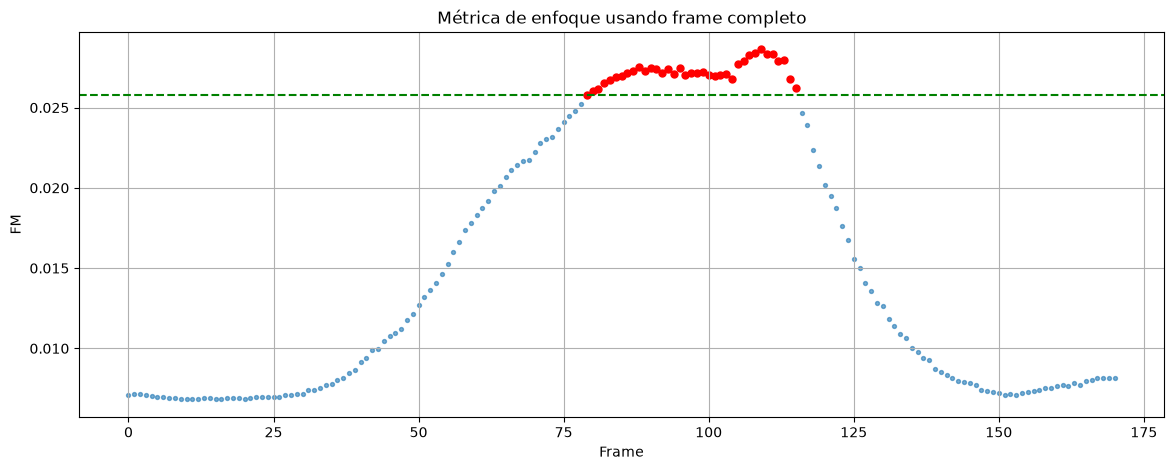

In [46]:
resultado_full = analizar_enfoque_video(
    ruta_video,
    usar_roi=False
)

Vemos que hay 37 frames enfocados según nuestro criterio. Todos son consecutivos y se encuentran en el medio del video, lo cual tiene sentido luego de mirar el video. 

Observamos también que ésto solo funciona porque nosotros sabemos a priori que los frames en el medio del video están enfocados y por éso pudimos establecer el criterio para definir un frame enfocado. Sin ésta información sería imposible detectar frames enfocados automáticamente por medio de un algoritmo, ya que el valor de la métrica depende del tamaño y contenido de la imágen. Por ejemplo, sabemos que para los frames de nuestro video un valor de métrica de 0,026 nos dice que el frame está enfocado, pero ése número solo tiene sentido en el contexto de la imágen que muestra el video. En otras palabras, ésta métrica es útil para comparar la misma imágen (o imágenes muy similares). Las imágenes del paper (la misma imágen luego de aplicarle distintos filtros) y el video (prácticamente la misma imágen con distintos niveles de enfoque) son casos en los que debería funcionar.

Ésto se puede apreciar en la comparación que hace el paper al plotear la métrica aplicada a varias imágenes a medida que se aumenta el difuminado. Las ordenadas al origen de cada imágen (métrica de la imágen enfocada) son muy distintas para cada imágen:

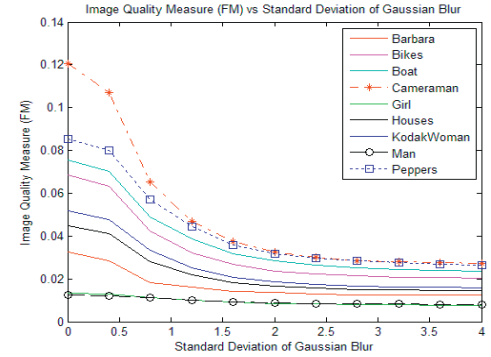


Ahora definimos una región de interés cuadrada centrada en el frame de approx. 10 % del área del frame completo

Cargando video: videos/focus_video.mov
FM máximo: 0.347
Umbral (90%): 0.313
Frames enfocados:
[91, 93, 95, 96, 97, 99, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113]


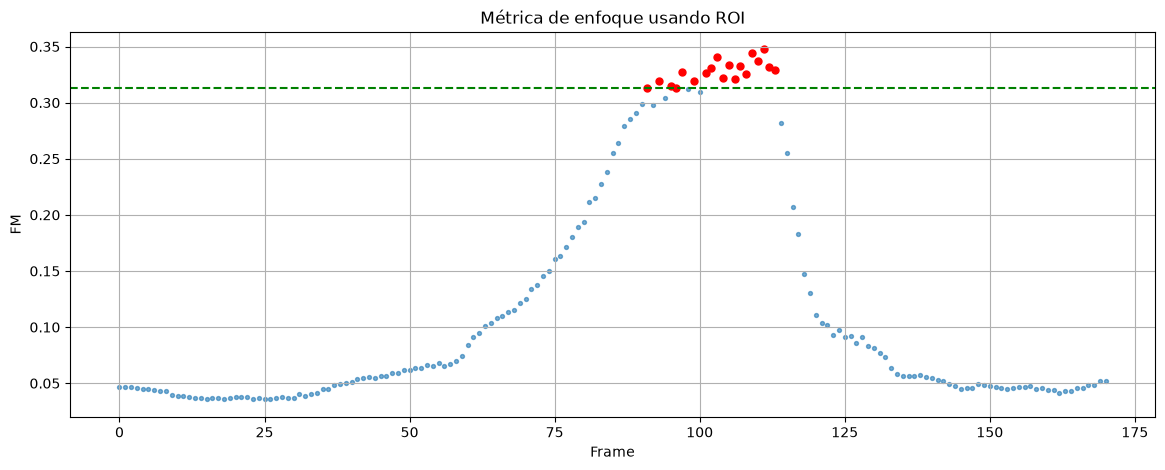

In [47]:
resultado_roi = analizar_enfoque_video(
    ruta_video,
    usar_roi=True
)

In [11]:
frames_full = resultado_full["frames_enfocados"]
frames_roi  = resultado_roi["frames_enfocados"]

comunes = np.intersect1d(frames_full, frames_roi)

distintos = np.setxor1d(frames_full, frames_roi)

print(f"Coinciden en {len(comunes)} frames")
print(comunes)

print(f"Frames donde difieren: {len(distintos)}")
print(distintos)

Coinciden en 19 frames
[ 91  93  95  96  97  99 101 102 103 104 105 106 107 108 109 110 111 112
 113]
Frames donde difieren: 18
[ 79  80  81  82  83  84  85  86  87  88  89  90  92  94  98 100 114 115]


In [35]:
import numpy as np


def roi_central(frame, porcentaje_area=0.05):
    """
    Extrae una ROI cuadrada centrada cuya área representa
    aproximadamente porcentaje_area del área total del frame.
    """

    if frame is None or frame.size == 0:
        raise ValueError("El frame está vacío o no es válido.")

    if not 0 < porcentaje_area <= 1:
        raise ValueError("porcentaje_area debe estar entre 0 y 1.")

    alto, ancho = frame.shape[:2]

    area_total = alto * ancho
    lado_roi = int(np.sqrt(area_total * porcentaje_area))

    # Impide que la ROI sea mayor que el frame
    lado_roi = min(lado_roi, alto, ancho)

    centro_x = ancho // 2
    centro_y = alto // 2

    x_inicio = centro_x - lado_roi // 2
    y_inicio = centro_y - lado_roi // 2

    x_fin = x_inicio + lado_roi
    y_fin = y_inicio + lado_roi

    roi = frame[y_inicio:y_fin, x_inicio:x_fin].copy()

    return roi

In [ ]:
def crear_video_marcado(
    ruta_entrada,
    ruta_salida,
    frames_enfocados,
    frames_unsharp=None,
    aplicar_unsharp=False,
    k=2.5,
    kernel=(7, 7),
    sigma=0.5,
    texto_enfocado="ENFOCADO",
    texto_unsharp="UNSHARP MASKING"
):

    frames_enfocados_set = set(
        np.asarray(frames_enfocados, dtype=int).tolist()
    )

    if frames_unsharp is None:
        frames_unsharp_set = set()
    else:
        frames_unsharp_set = set(
            np.asarray(frames_unsharp, dtype=int).tolist()
        )

    captura = cv2.VideoCapture(ruta_entrada)

    if not captura.isOpened():
        raise ValueError(
            f"No se pudo abrir el video: {ruta_entrada}"
        )

    fps = captura.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        fps = 30.0

    ancho = int(
        captura.get(cv2.CAP_PROP_FRAME_WIDTH)
    )

    alto = int(
        captura.get(cv2.CAP_PROP_FRAME_HEIGHT)
    )

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    escritor = cv2.VideoWriter(
        ruta_salida,
        fourcc,
        fps,
        (ancho, alto)
    )

    if not escritor.isOpened():
        captura.release()

        raise ValueError(
            f"No se pudo crear el video: {ruta_salida}"
        )

    indice_frame = 0

    try:
        while True:
            ret, frame = captura.read()

            if not ret:
                break

            # Aplicar unsharp solo a los frames seleccionados
            if (
                aplicar_unsharp
                and indice_frame in frames_unsharp_set
            ):
                frame = aplicar_unsharp_masking(
                    frame,
                    k=k,
                    kernel=kernel,
                    sigma=sigma
                )

                cv2.putText(
                    frame,
                    texto_unsharp,
                    (30, alto - 30),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (0, 255, 255),
                    2,
                    cv2.LINE_AA
                )

            # Enmarcar frames enfocados
            if indice_frame in frames_enfocados_set:
                cv2.rectangle(
                    frame,
                    (10, 10),
                    (ancho - 10, alto - 10),
                    (0, 0, 255),
                    thickness=8
                )

                cv2.putText(
                    frame,
                    f"{texto_enfocado} "
                    f"(frame {indice_frame})",
                    (30, 50),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1.0,
                    (0, 0, 255),
                    2,
                    cv2.LINE_AA
                )

            escritor.write(frame)
            indice_frame += 1

    finally:
        captura.release()
        escritor.release()

    print(f"Video guardado en: {ruta_salida}")

    return ruta_salida

In [28]:
def reproducir_videos_lado_a_lado(
    ruta_izquierda,
    ruta_derecha,
    titulo_izquierda="Original",
    titulo_derecha="Procesado"
):

    video_izq = cv2.VideoCapture(ruta_izquierda)
    video_der = cv2.VideoCapture(ruta_derecha)

    if not video_izq.isOpened():
        raise ValueError(f"No se pudo abrir: {ruta_izquierda}")

    if not video_der.isOpened():
        raise ValueError(f"No se pudo abrir: {ruta_derecha}")

    fps = video_izq.get(cv2.CAP_PROP_FPS)
    retardo_ms = round(1000 / fps) if fps > 0 else 33
    cv2.namedWindow("Comparacion", cv2.WINDOW_NORMAL)
    while True:

        ret_izq, frame_izq = video_izq.read()
        ret_der, frame_der = video_der.read()

        if not ret_izq or not ret_der:
            break

        if frame_der.shape[:2] != frame_izq.shape[:2]:
            frame_der = cv2.resize(
                frame_der,
                (frame_izq.shape[1], frame_izq.shape[0])
            )

        cv2.putText(
            frame_izq,
            titulo_izquierda,
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 255, 255),
            2
        )

        cv2.putText(
            frame_der,
            titulo_derecha,
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 255, 255),
            2
        )

        comparacion = cv2.hconcat([frame_izq, frame_der])

        cv2.imshow(
            "Comparacion",
            comparacion
        )

        if cv2.waitKey(retardo_ms) & 0xFF == ord("q"):
            break

    video_izq.release()
    video_der.release()
    cv2.destroyAllWindows()

In [17]:
ruta_video_marcado = ("videos/focus_video_marcado.mp4")
crear_video_marcado(
    ruta_entrada=ruta_video,
    ruta_salida=ruta_video_marcado,
    frames_enfocados=frames_full,
    aplicar_unsharp=False
)

Video guardado en: videos/focus_video_marcado.mp4


'videos/focus_video_marcado.mp4'

In [30]:
reproducir_videos_lado_a_lado(ruta_video, ruta_video_marcado, titulo_izquierda="Original", titulo_derecha="Enmarcado")

In [ ]:
def unsharp_mask(
    imagen,
    k=2.5,
    kernel_size=(7, 7),
    sigma=0.5
):

    gauss = cv2.GaussianBlur(
        imagen,
        kernel_size,
        sigma
    )

    imagen_sharp = cv2.addWeighted(
        imagen,
        k + 1,
        gauss,
        -k,
        0
    )

    return imagen_sharp

In [31]:
fm_max = resultado_full["fm_max"]

umbral_80 = 0.80 * fm_max
umbral_90 = 0.90 * fm_max

frames_candidatos = np.where(
    (resultado_full["metricas"] >= umbral_80) &
    (resultado_full["metricas"] < umbral_90)
)[0]

print(frames_candidatos)

[ 72  73  74  75  76  77  78 116 117]


In [34]:
captura = cv2.VideoCapture(ruta_video)

metricas_mejoradas = (
    resultado_full["metricas"].copy()
)

indice = 0

while True:

    ret, frame = captura.read()

    if not ret:
        break

    if indice in frames_candidatos:

        frame_sharp = unsharp_mask(
            frame,
            k=2.5
        )

        metricas_mejoradas[indice] = (
            calc_metrica_enfoque(
                frame_sharp
            )
        )

    indice += 1

captura.release()